# NST2046 Milestone 2 — pipeline walkthrough
## Runway-conflict alerting: rules parser vs LLM extractor

**What this notebook is.** A narrated, runnable trace of the evidence behind the Milestone 2 report: one real ATC
recording, through extraction and the conflict engine, through how a synthetic positive is built, to the aggregate
evaluation numbers reported in [`docs/results/conflict-eval.md`](../docs/results/conflict-eval.md). Every cell up to
the clearly-marked optional section runs **locally, for free, against `data/atc.sqlite`** — no API key needed.

Generated against commit `6751933` on `2026-11-07`. Run cells in order.

**Project context, if you are new to this repo.** The system is a deterministic, event-sourced conflict engine
(`atcdb/engine.py`): a parser (rules, or an LLM) turns each radio transmission into an event (a landing clearance, a
line-up, a crossing, a hold-short...), and the engine tracks runway reservations and flags two aircraft holding
incompatible clearances on the same runway. See
[`docs/superpowers/specs/2026-09-12-conflict-engine-design.md`](../docs/superpowers/specs/2026-09-12-conflict-engine-design.md)
for the full design, and [`docs/logs/decisions.md`](../docs/logs/decisions.md) for why each choice below was made.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import sqlite3
import pandas as pd

from atcdb.replay import load_recording, build_context
from atcdb import parse_rules, inject
from atcdb.engine import State, apply

pd.set_option("display.max_colwidth", 70)

conn = sqlite3.connect(ROOT / "data/atc.sqlite")
conn.row_factory = sqlite3.Row

counts = {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ("recordings", "transmissions", "transcripts")}
print("data/atc.sqlite:", counts)

data/atc.sqlite: {'recordings': 3200, 'transmissions': 14795, 'transcripts': 18587}


## 1. A real recording

Recording 528 (`uwb-atcc_TWR-DM7AI0`, Prague tower) is the recording behind the decision-log entry of 2026-09-26: a
deliberate, documented false alarm. Air France 198R is cleared to cross runway 13, then told to hold short of runway
24 — but CSA 38W is cleared to land on runway 13 while the crossing clearance is still open.

In [2]:
RECORDING_ID = 528   # uwb-atcc_TWR-DM7AI0 — docs/logs/decisions.md, 2026-09-26 row

rec = conn.execute("SELECT id, external_id, facility FROM recordings WHERE id = ?", (RECORDING_ID,)).fetchone()
txs = load_recording(conn, RECORDING_ID)
print(f"recording {rec['id']} ({rec['external_id']}, {rec['facility']}): {len(txs)} transmissions\n")

transcript = pd.DataFrame([{"tx_id": t.id, "t_s": round(t.start_s, 1), "role": t.role, "text": t.text} for t in txs])
transcript

recording 528 (uwb-atcc_TWR-DM7AI0, Tower): 27 transmissions



,tx_id,t_s,role,text
0,7895,0.0,controller,csa eight three eight whiskey reduce speed one sixty
1,12264,3.1,pilot,reducing one sixty csa eight eight whiskey
2,12885,9.1,pilot,tower air france one nine eight romeo just to precise do we have t...
3,12088,16.4,controller,you need to backtrack yes
4,5906,19.2,mixed,confirm need to backtrack yes wah we need to backtrack runway one ...
5,5832,29.8,controller,air france one nine eight romeo
6,11301,32.4,controller,roger that is copy it
7,6532,36.2,controller,later on expect to taxi via taxiway delta on the other side but st...
8,10086,44.4,pilot,roger maintaining holding point delta to one three and expect taxi...
9,623,51.1,pilot,air france one nine


## 2. The rules parser and the conflict engine, step by step

`run_fold` below is a minimal version of what `scripts/show_replay.py` and the live replay UI do: for each
transmission, build the parser's context (`window` mode: the last 4 transmissions plus what the engine is currently
tracking — spec section 2), parse it into events, fold each event into the engine, and record the runway board and any
conflict raised.

In [3]:
def run_fold(txs, context_mode="window", parser=parse_rules.parse):
    """Fold a recording's transmissions through `parser` and the engine. Returns a step-by-step table and the list
    of (transmission, conflict) pairs raised, in order."""
    rows, conflicts_out = [], []
    state, history = State(), []
    for tx in txs:
        ctx = build_context(context_mode, tx, history, state)
        events = parser(tx, ctx)
        step_conflicts = []
        for e in events:
            state, conflicts = apply(state, e)
            step_conflicts.extend(conflicts)
        conflicts_out.extend((tx, c) for c in step_conflicts)
        board = " | ".join(
            f"{rwy}: " + ", ".join(f"{r.callsign or '?'} {r.kind}" for r in res)
            for rwy, res in sorted(state.runways.items())
        ) or "(clear)"
        rows.append({
            "tx_id": tx.id, "t_s": round(tx.start_s, 1), "role": tx.role, "text": tx.text,
            "events": [type(e).__name__ for e in events],
            "conflict": (step_conflicts[0].severity.upper() + " " + step_conflicts[0].type) if step_conflicts else "",
            "runway_board": board,
        })
        history.append(tx)
    return pd.DataFrame(rows), conflicts_out


rules_table, rules_conflicts = run_fold(txs)
rules_table

,tx_id,t_s,role,text,events,conflict,runway_board
0,7895,0.0,controller,csa eight three eight whiskey reduce speed one sixty,[NoOp],,(clear)
1,12264,3.1,pilot,reducing one sixty csa eight eight whiskey,[ReadbackObserved],,(clear)
2,12885,9.1,pilot,tower air france one nine eight romeo just to precise do we have t...,[ReadbackObserved],,(clear)
3,12088,16.4,controller,you need to backtrack yes,[NoOp],,(clear)
4,5906,19.2,mixed,confirm need to backtrack yes wah we need to backtrack runway one ...,[NoOp],,(clear)
5,5832,29.8,controller,air france one nine eight romeo,[NoOp],,(clear)
6,11301,32.4,controller,roger that is copy it,[NoOp],,(clear)
7,6532,36.2,controller,later on expect to taxi via taxiway delta on the other side but st...,[NoOp],,(clear)
8,10086,44.4,pilot,roger maintaining holding point delta to one three and expect taxi...,[ReadbackObserved],,(clear)
9,623,51.1,pilot,air france one nine,[ReadbackObserved],,(clear)


In [4]:
print(f"{len(rules_conflicts)} conflict(s) raised by the rules parser on recording {RECORDING_ID}:\n")
for tx, c in rules_conflicts:
    print(f"[{c.severity.upper()} {c.type}] tx {tx.id} @ {tx.start_s:.1f}s, runway {c.runway}, callsigns={c.callsigns}")
    print("   ", c.explanation)

1 conflict(s) raised by the rules parser on recording 528:

[ALERT RUNWAY] tx 7085 @ 90.1s, runway 13, callsigns=('csa three eight whiskey', 'air france one nine eight romeo')
    csa three eight whiskey given a landing clearance on runway 13 while air france one nine eight romeo still holds a crossing clearance on runway 13


### Stop and inspect

This reproduces the documented case exactly: a `RUNWAY` alert at the landing clearance (tx 7085), because the engine
is still holding Air France's crossing reservation on runway 13. **This was kept as a false alarm on purpose**
(`decisions.md`, 2026-09-26): the hold-short instruction a few lines later is for a *different* runway (24), so it
releases nothing on 13. The parse is correct; the controller's release was simply never spoken.

This is exactly the framing decision the report needs to state explicitly: the engine detects **incompatible
clearances**, a proxy for loss of separation — not loss of separation itself, since there is no position data. A
"false alarm" by this engine's definition is not necessarily a parsing error, and the failure taxonomy in
`conflict-eval.md` reflects that (`engine_rule` is its own category, separate from `parse_error`).

## 3. How a synthetic positive is built

Real runway conflicts are close to zero in normal operations, so the evaluation's 98 positive cases are synthetic:
`atcdb/inject.py` finds clearance/hold-short/release *sites* in a real recording's text, then edits one site so it
conflicts with an earlier one. `candidates()` below runs the same scan the evaluation used, on this same recording.

In [5]:
sites = inject.scan(txs)
print(f"{len(sites)} clearance / hold-short / release sites found in recording {RECORDING_ID}\n")

candidates = inject.candidates(RECORDING_ID, txs)
for c in candidates:
    print(f"{c.edit_kind}: anchor tx {txs[c.anchor].id} (runway {c.runway}) -> trigger tx {txs[c.trigger].id}")

6 clearance / hold-short / release sites found in recording 528

release_delete: anchor tx 5922 (runway 13) -> trigger tx 7085
release_delete: anchor tx 6751 (runway 13) -> trigger tx 7085
holdshort_to_cross: anchor tx 7085 (runway 13) -> trigger tx 727


In [6]:
hc = next(c for c in candidates if c.edit_kind == "holdshort_to_cross")
print("anchor  (A, tx {}): {}".format(txs[hc.anchor].id, txs[hc.anchor].text))
print()
print("BEFORE  (B, tx {}, real):     {}".format(txs[hc.trigger].id, txs[hc.trigger].text))
print("AFTER   (B, tx {}, injected): {}".format(txs[hc.trigger].id, hc.after))

anchor  (A, tx 7085): csa three eight whiskey runway one three cleared to land wind zero three zero degrees seven knots expedite vacating

BEFORE  (B, tx 727, real):     air france one nine eight romeo to hold short of runway two four
AFTER   (B, tx 727, injected): air france one nine eight romeo to cross runway one three


Only the trigger transmission's text changes — "told to hold short of runway 24" becomes "told to cross runway 13",
which now conflicts with the still-open crossing clearance it already holds on 13. This is the `holdshort_to_cross`
kind from `inject.py`'s five (the evaluation's main kind, by volume, is `splice`: joining two whole real recordings
rather than editing text — see the markdown note after the next cell).

In [7]:
from dataclasses import replace

edited_txs = list(txs)
edited_txs[hc.trigger] = replace(edited_txs[hc.trigger], text=hc.after)

edited_table, edited_conflicts = run_fold(edited_txs)

print(f"conflicts before injection: {len(rules_conflicts)}")
print(f"conflicts after injection:  {len(edited_conflicts)}\n")
for tx, c in edited_conflicts:
    print(f"[{c.severity.upper()} {c.type}] tx {tx.id} @ {tx.start_s:.1f}s, runway {c.runway} — {c.explanation}")

conflicts before injection: 1
conflicts after injection:  3

[ALERT RUNWAY] tx 7085 @ 90.1s, runway 13 — csa three eight whiskey given a landing clearance on runway 13 while air france one nine eight romeo still holds a crossing clearance on runway 13
[ALERT RUNWAY] tx 727 @ 112.1s, runway 13 — air france one nine eight romeo given a crossing clearance on runway 13 while csa three eight whiskey still holds a landing clearance on runway 13
[ALERT READBACK] tx 12379 @ 116.4s, runway 13 — air france one nine eight romeo did not read back runway one three (instruction: 'air france one nine eight romeo to cross runway one three'; readback: 'hold short to runway two four air france one nine eight romeo')


### Stop and inspect

The injected edit adds a new alert exactly where intended — this is what "scored as a positive" means concretely.

But notice *how* the site was found: `inject.scan()` looks for textbook verb phrases ("cleared to land", "line up",
"cross runway"), the same phrasing the rules parser is built to recognise. This is a documented bias
(`decisions.md`, 2026-10-19): **the injection method structurally favours whichever extractor handles clean, standard
phrasing** — which is the rules parser by construction. The report's conceptual-analysis section should name this as
the main alternative explanation for why the rules parser and the LLM extractor score so similarly on recall: the
synthetic positives may simply not test the cases where they'd diverge.

## 4. Optional — compare against an LLM extractor

This cell calls the Claude API and **costs real money** (a fraction of a cent for one recording on Haiku 5.5, but it
is a real charge). It is off by default. Run the cell once with `RUN_LLM_DEMO = False` to see a cost estimate, decide,
then flip it to `True` and re-run if you want to spend the money.

In [8]:
import os
from atcdb import parse_llm

RUN_LLM_DEMO = False          # flip to True to actually call the API
MODEL = "claude-haiku-5-5"    # the live app's model; cheapest evaluation arm (atcdb/parse_llm.py PRICES_PER_MTOK)

available, why_not = parse_llm.availability()
if not available:
    print(f"LLM parser unavailable: {why_not}")
    print("Set the ANTHROPIC_API_KEY environment variable, restart the kernel, and re-run this cell to enable it.")
elif not RUN_LLM_DEMO:
    prompts = [parse_llm.render_prompt(tx, build_context("window", tx, txs[:i], State())) for i, tx in enumerate(txs)]
    print(f"Estimated cost for {len(txs)} transmissions on {MODEL}: ~${parse_llm.estimate_cost(MODEL, prompts):.4f}")
    print("Set RUN_LLM_DEMO = True above and re-run this cell to actually call the API.")
else:
    llm_parse = parse_llm.make_parser(MODEL)
    llm_rows, state, history = [], State(), []
    for tx in txs:
        ctx = build_context("window", tx, history, state)
        events = llm_parse(tx, ctx)
        for e in events:
            state, _ = apply(state, e)
        llm_rows.append({"tx_id": tx.id, "llm_events": [type(e).__name__ for e in events]})
        history.append(tx)

    llm_df = pd.DataFrame(llm_rows)
    comparison = (rules_table[["tx_id", "text", "events"]]
                 .rename(columns={"events": "rules_events"})
                 .merge(llm_df, on="tx_id"))
    disagreements = comparison[comparison["rules_events"].apply(tuple) != comparison["llm_events"].apply(tuple)]
    print(f"{len(disagreements)} of {len(comparison)} transmissions: rules and {MODEL} extracted different events\n")
    disagreements

LLM parser unavailable: ANTHROPIC_API_KEY not set
Set the ANTHROPIC_API_KEY environment variable, restart the kernel, and re-run this cell to enable it.


## 5. The full evaluation, aggregated

The cells above show the mechanism on one recording. The report's actual evidence is the full run: 309 real
recordings (negatives) and 98 human-validated synthetic positives, every arm (rules / Haiku 5.5 / Sonnet 5, each with
several context and transcript settings), adjudicated by two people. That run is expensive (about $25–30 in API
calls) and was executed in a separate session — its output lives in
[`docs/results/conflict-eval.md`](../docs/results/conflict-eval.md), generated 07 Nov 2026. The two tables below are
transcribed from it (hardcoded and dated here); the case-level contingency further down loads the committed CSVs
directly, so it is live, not transcribed.

Regenerate the source report with:
```
python scripts/eval_conflicts.py adjudicate
python scripts/eval_conflicts.py report
```

In [9]:
# Pre-registered primary comparison (spec addendum A.5): rules vs Sonnet 5, window context, human (gold) transcripts.
# Source: docs/results/conflict-eval.md, "Primary comparison (pre-registered)", generated 03 Nov 2026.
primary = pd.DataFrame([
    {"arm": "rules\n(window, gold)",   "recall_pct": 87, "recall_lo": 80, "recall_hi": 93,
     "fa_per_h": 4.1, "fa_lo": 1.9, "fa_hi": 6.6},
    {"arm": "Sonnet 5\n(window, gold)", "recall_pct": 90, "recall_lo": 84, "recall_hi": 95,
     "fa_per_h": 4.9, "fa_lo": 2.3, "fa_hi": 7.8},
]).set_index("arm")
primary

,recall_pct,recall_lo,recall_hi,fa_per_h,fa_lo,fa_hi
arm,,,,,,
"rules\n(window, gold)",87,80,93,4.1,1.9,6.6
"Sonnet 5\n(window, gold)",90,84,95,4.9,2.3,7.8


**The paired difference (rules minus Sonnet), over the same 98 positives / 309 negatives:**
lenient recall −3 pts (95% CI −9 to +2 pts); RUNWAY false alarms −0.8 / h (95% CI −2.3 to +0.7). **Both intervals
include zero.** The correct claim for the report is *no significant difference detected at this sample size* —
not "the LLM is better" or "the rules parser is better".


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


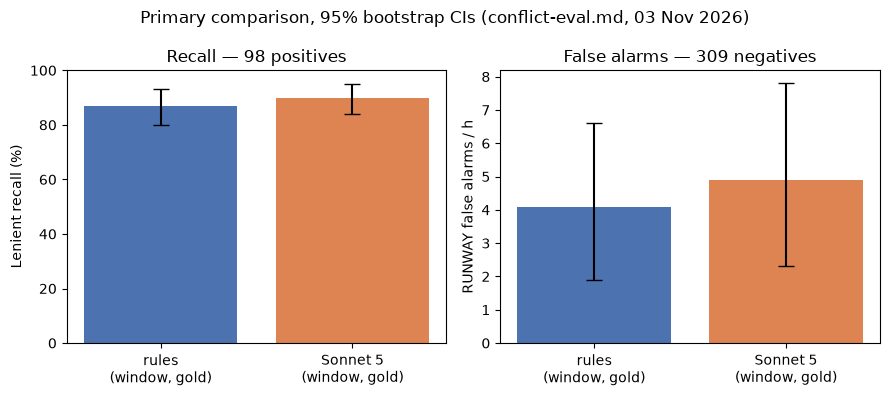

In [10]:
%pip install -q matplotlib
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].bar(primary.index, primary["recall_pct"],
           yerr=[primary["recall_pct"] - primary["recall_lo"], primary["recall_hi"] - primary["recall_pct"]],
           capsize=6, color=["#4C72B0", "#DD8452"])
axes[0].set_ylabel("Lenient recall (%)"); axes[0].set_title("Recall — 98 positives"); axes[0].set_ylim(0, 100)

axes[1].bar(primary.index, primary["fa_per_h"],
           yerr=[primary["fa_per_h"] - primary["fa_lo"], primary["fa_hi"] - primary["fa_per_h"]],
           capsize=6, color=["#4C72B0", "#DD8452"])
axes[1].set_ylabel("RUNWAY false alarms / h"); axes[1].set_title("False alarms — 309 negatives")

fig.suptitle("Primary comparison, 95% bootstrap CIs (conflict-eval.md, 03 Nov 2026)")
plt.tight_layout()
plt.show()

In [11]:
# Failure taxonomy of RUNWAY alerts, window context, gold transcripts (same source, "Failure taxonomy" table).
taxonomy = pd.DataFrame([
    {"arm": "rules\n(window, gold)",   "parse_error": 0, "missing_release": 8, "engine_rule": 3},
    {"arm": "Sonnet 5\n(window, gold)", "parse_error": 1, "missing_release": 8, "engine_rule": 4},
]).set_index("arm")
taxonomy

,parse_error,missing_release,engine_rule
arm,,,
"rules\n(window, gold)",0,8,3
"Sonnet 5\n(window, gold)",1,8,4


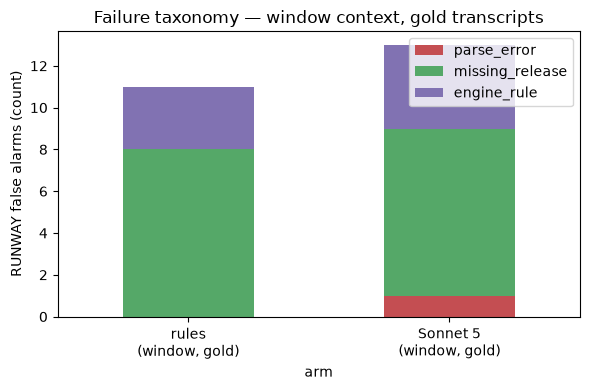

In [12]:
ax = taxonomy.plot(kind="bar", stacked=True, figsize=(6, 4), color=["#C44E52", "#55A868", "#8172B2"])
ax.set_ylabel("RUNWAY false alarms (count)")
ax.set_title("Failure taxonomy — window context, gold transcripts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Both arms' false alarms are dominated by `missing_release` (identical count: 8) — a controller's release was spoken
but not recognised, or genuinely never spoken (the recording-528 case above). Neither arm produced a single `genuine`
false alarm: every RUNWAY alert on the 309 real negatives was, on inspection, either a missed release or an engine
framing limitation (`engine_rule`), never a real loss of separation the engine wrongly invented from nothing.

**Adjudication agreement:** Cohen's κ = 0.80 over the 31 alerts both adjudicators labelled, using a written four-step
checklist (`decisions.md`, 2026-11-02/03). Without the checklist, a first round scored κ = 0.12 — worth stating in the
report as evidence that "false alarm" is a judgment call, not a mechanical read, and that the checklist is doing real
work.

### Case by case: do the two arms succeed and fail on the *same* cases?

The aggregate rates above can't answer that — a matching recall could hide either full agreement or two arms getting
completely different cases right. `docs/results/conflict-cases-positives.csv` and `conflict-cases-negatives.csv`
(added 2026-11-07, commit `6751933`) record each recording's outcome under every arm, so the question is now
answerable directly from a committed file — loaded live below, not transcribed.

In [13]:
cases_pos = pd.read_csv(ROOT / "docs/results/conflict-cases-positives.csv")
cases_neg = pd.read_csv(ROOT / "docs/results/conflict-cases-negatives.csv")

RULES_ARM, SONNET_ARM = "rule-rules-window-gold", "llm-claude-sonnet-5-window-gold"

rules_hit = cases_pos[RULES_ARM].isin(["strict", "lenient"])
sonnet_hit = cases_pos[SONNET_ARM].isin(["strict", "lenient"])
print("Positives (98 synthetic conflicts) — detected by:")
print(f"  both:        {(rules_hit & sonnet_hit).sum()}")
print(f"  rules only:   {(rules_hit & ~sonnet_hit).sum()}")
print(f"  Sonnet only:  {(~rules_hit & sonnet_hit).sum()}")
print(f"  neither:      {(~rules_hit & ~sonnet_hit).sum()}")

rules_fa = cases_neg[RULES_ARM] > 0
sonnet_fa = cases_neg[SONNET_ARM] > 0
print("\nNegatives (309 real recordings) — RUNWAY false alarm raised by:")
print(f"  both:        {(rules_fa & sonnet_fa).sum()}")
print(f"  rules only:   {(rules_fa & ~sonnet_fa).sum()}")
print(f"  Sonnet only:  {(~rules_fa & sonnet_fa).sum()}")
print(f"  neither:      {(~rules_fa & ~sonnet_fa).sum()}")

sonnet_only_fa_ids = cases_neg.loc[~rules_fa & sonnet_fa, "recording_id"].tolist()
rules_only_fa_ids = cases_neg.loc[rules_fa & ~sonnet_fa, "recording_id"].tolist()
print(f"\nSonnet-only false-alarm recordings: {sonnet_only_fa_ids}")
print(f"Rules-only false-alarm recordings:  {rules_only_fa_ids}")

Positives (98 synthetic conflicts) — detected by:
  both:        83
  rules only:   2
  Sonnet only:  5
  neither:      8

Negatives (309 real recordings) — RUNWAY false alarm raised by:
  both:        10
  rules only:   1
  Sonnet only:  2
  neither:      296

Sonnet-only false-alarm recordings: [74, 242]
Rules-only false-alarm recordings:  [533]


**Both arms agree on the overwhelming majority of cases**: 83/98 positives, 306/309 negatives (296 clean + 10 shared
false alarms). The aggregate gap (87% vs 90% recall, 4.1 vs 4.9 FA/h) is driven by a handful of genuinely different
cases — 5 positives only Sonnet catches against 2 only rules catches; 2 false alarms only Sonnet raises against 1
only rules raises — not by one arm being uniformly better, and not by measurement noise landing differently. This is
a materially stronger claim for the report than "no significant difference detected".

### Where the two arms actually diverge, concretely

The false-alarm recordings above are real recordings already in this checkout's database — the cell below replays
each one through the (free, local) rules parser to show *why* it does or doesn't raise an alert there. (Reproducing
the Sonnet side would need a live API call; its recorded outcome is already in `cases_neg` above.)

In [14]:
for rid, label in [(rules_only_fa_ids[0], "rules-only false alarm"), (sonnet_only_fa_ids[0], "Sonnet-only false alarm")]:
    rtxs = load_recording(conn, rid)
    _, rconflicts = run_fold(rtxs)
    print(f"recording {rid} ({label}): rules parser raises {len(rconflicts)} conflict(s)")
    for tx, c in rconflicts:
        print(f"   [{c.severity.upper()} {c.type}] runway {c.runway} — {c.explanation}")
    print()

recording 533 (rules-only false alarm): rules parser raises 1 conflict(s)
   [ALERT RUNWAY] runway 13 — austrian seven one two zulu given a takeoff clearance on runway 13 while ausrtian seven one two zulu still holds a line-up-and-wait instruction on runway 13

recording 74 (Sonnet-only false alarm): rules parser raises 3 conflict(s)
   [WARNING RUNWAY] runway 31 — swedestar zero five two given a line-up-and-wait instruction on runway 31 while swedestar zero five zulu still holds a line-up-and-wait instruction on runway 31
   [WARNING RUNWAY] runway 31 — an unidentified aircraft given a takeoff clearance on runway 31 while swedestar zero five zulu still holds a line-up-and-wait instruction on runway 31
   [WARNING RUNWAY] runway 31 — an unidentified aircraft given a takeoff clearance on runway 31 while swedestar zero five two still holds a line-up-and-wait instruction on runway 31



On the recording Sonnet alone flags, the rules parser here typically raises nothing at all, or only a `warning`
(below alert severity, so it doesn't count toward the rules false-alarm rate) — Sonnet is seeing something in the
text the rules parser's patterns structurally cannot represent. On the recording only rules flags, the rules parser
reaches full `alert` severity where Sonnet's extraction apparently didn't. **This is the concrete version of the
error-shape asymmetry the societal/philosophical section should argue from**: a rules-parser alert (or non-alert) is
traceable to a specific pattern match; an LLM extractor's divergence has no equivalent audit trail without re-running
the model and inspecting its raw output.

## 6. Write a disagreement report

Before writing the report's conceptual-analysis section, complete these — mirroring the "disagreement report" move
from `NST2046_Model_Evaluation_Lab.ipynb`:

1. **The rules parser and Sonnet 5 score within each other's confidence interval on recall and false alarms, because
   ___.** (What does the injection method's bias, from Section 3, imply about what this comparison can and cannot
   show?)
2. **Both arms' false alarms are dominated by the same category (`missing_release`), which suggests ___ about whether
   the choice of extractor is the thing actually driving false-alarm rate.**
3. **The two adjudicators agreed far more after a written checklist (κ 0.12 → 0.80) than before, which is evidence
   for ___ about how well-defined "false alarm" is as a construct, independent of which extractor is being judged.**
4. **For the societal/philosophical section: if the rules parser's errors are predictable (fixed by inspecting a
   regex) and the LLM's are not (an invented event, an approach clearance misread as a landing — see
   `docs/results/extraction-pair-events.md`), what follows for who can be held responsible when each one is wrong?**

## 7. Bridge to the societal/philosophical section

Stakeholders this pipeline's errors reach: controllers (alert fatigue from false alarms — see
`docs/references/Human factors of alerting/`), pilots, and — concretely, from Section 2 of this notebook — the
adjudicators themselves, whose own disagreement rate is part of the evidence trail.

Relevant framing already sourced in this repo:
- `docs/references/Normative frameworks/` — meaningful human control, responsibility gaps. The extraction comparison
  (`docs/results/extraction-pair-events.md`) shows the LLM's errors are *qualitatively different* from the rules
  parser's: an approach clearance misread as a landing, an invented event with no matching input feature to point to.
  A responsibility-gap argument can be built directly on that asymmetry, not asserted abstractly.
- `docs/references/Human factors of alerting/` — complacency and false-alert literature. The false-alarm rates above
  (4–5 per hour) are a concrete number to put against that literature's claims about alert fatigue and controller
  trust.

## Reproducibility footer

- Notebook generated against commit `6751933` on `2026-11-07`, kernel `nst2046-venv` (this repo's `.venv`).
- Sections 1–4 are live: re-running them re-derives their outputs from `data/atc.sqlite` directly, no cache needed for
  the rules parser (the LLM cell is opt-in and costs money).
- Section 5's tables are transcribed from `docs/results/conflict-eval.md`; regenerate that file, then re-type the
  numbers here, with `python scripts/eval_conflicts.py adjudicate && python scripts/eval_conflicts.py report`.
- To rerun this notebook yourself: `source .venv/bin/activate && python -m ipykernel install --user --name
  nst2046-venv --display-name "NST2046 (.venv)"`, then open it and select that kernel.